# Importing

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
from matplotlib.font_manager import FontProperties
rcParams.update({
    'figure.autolayout': False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    })
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

RESULTS_DIR = 'results'
pt1_df = pd.read_csv(f'{RESULTS_DIR}/ccn_pt1.csv')

# Part 1

## v2

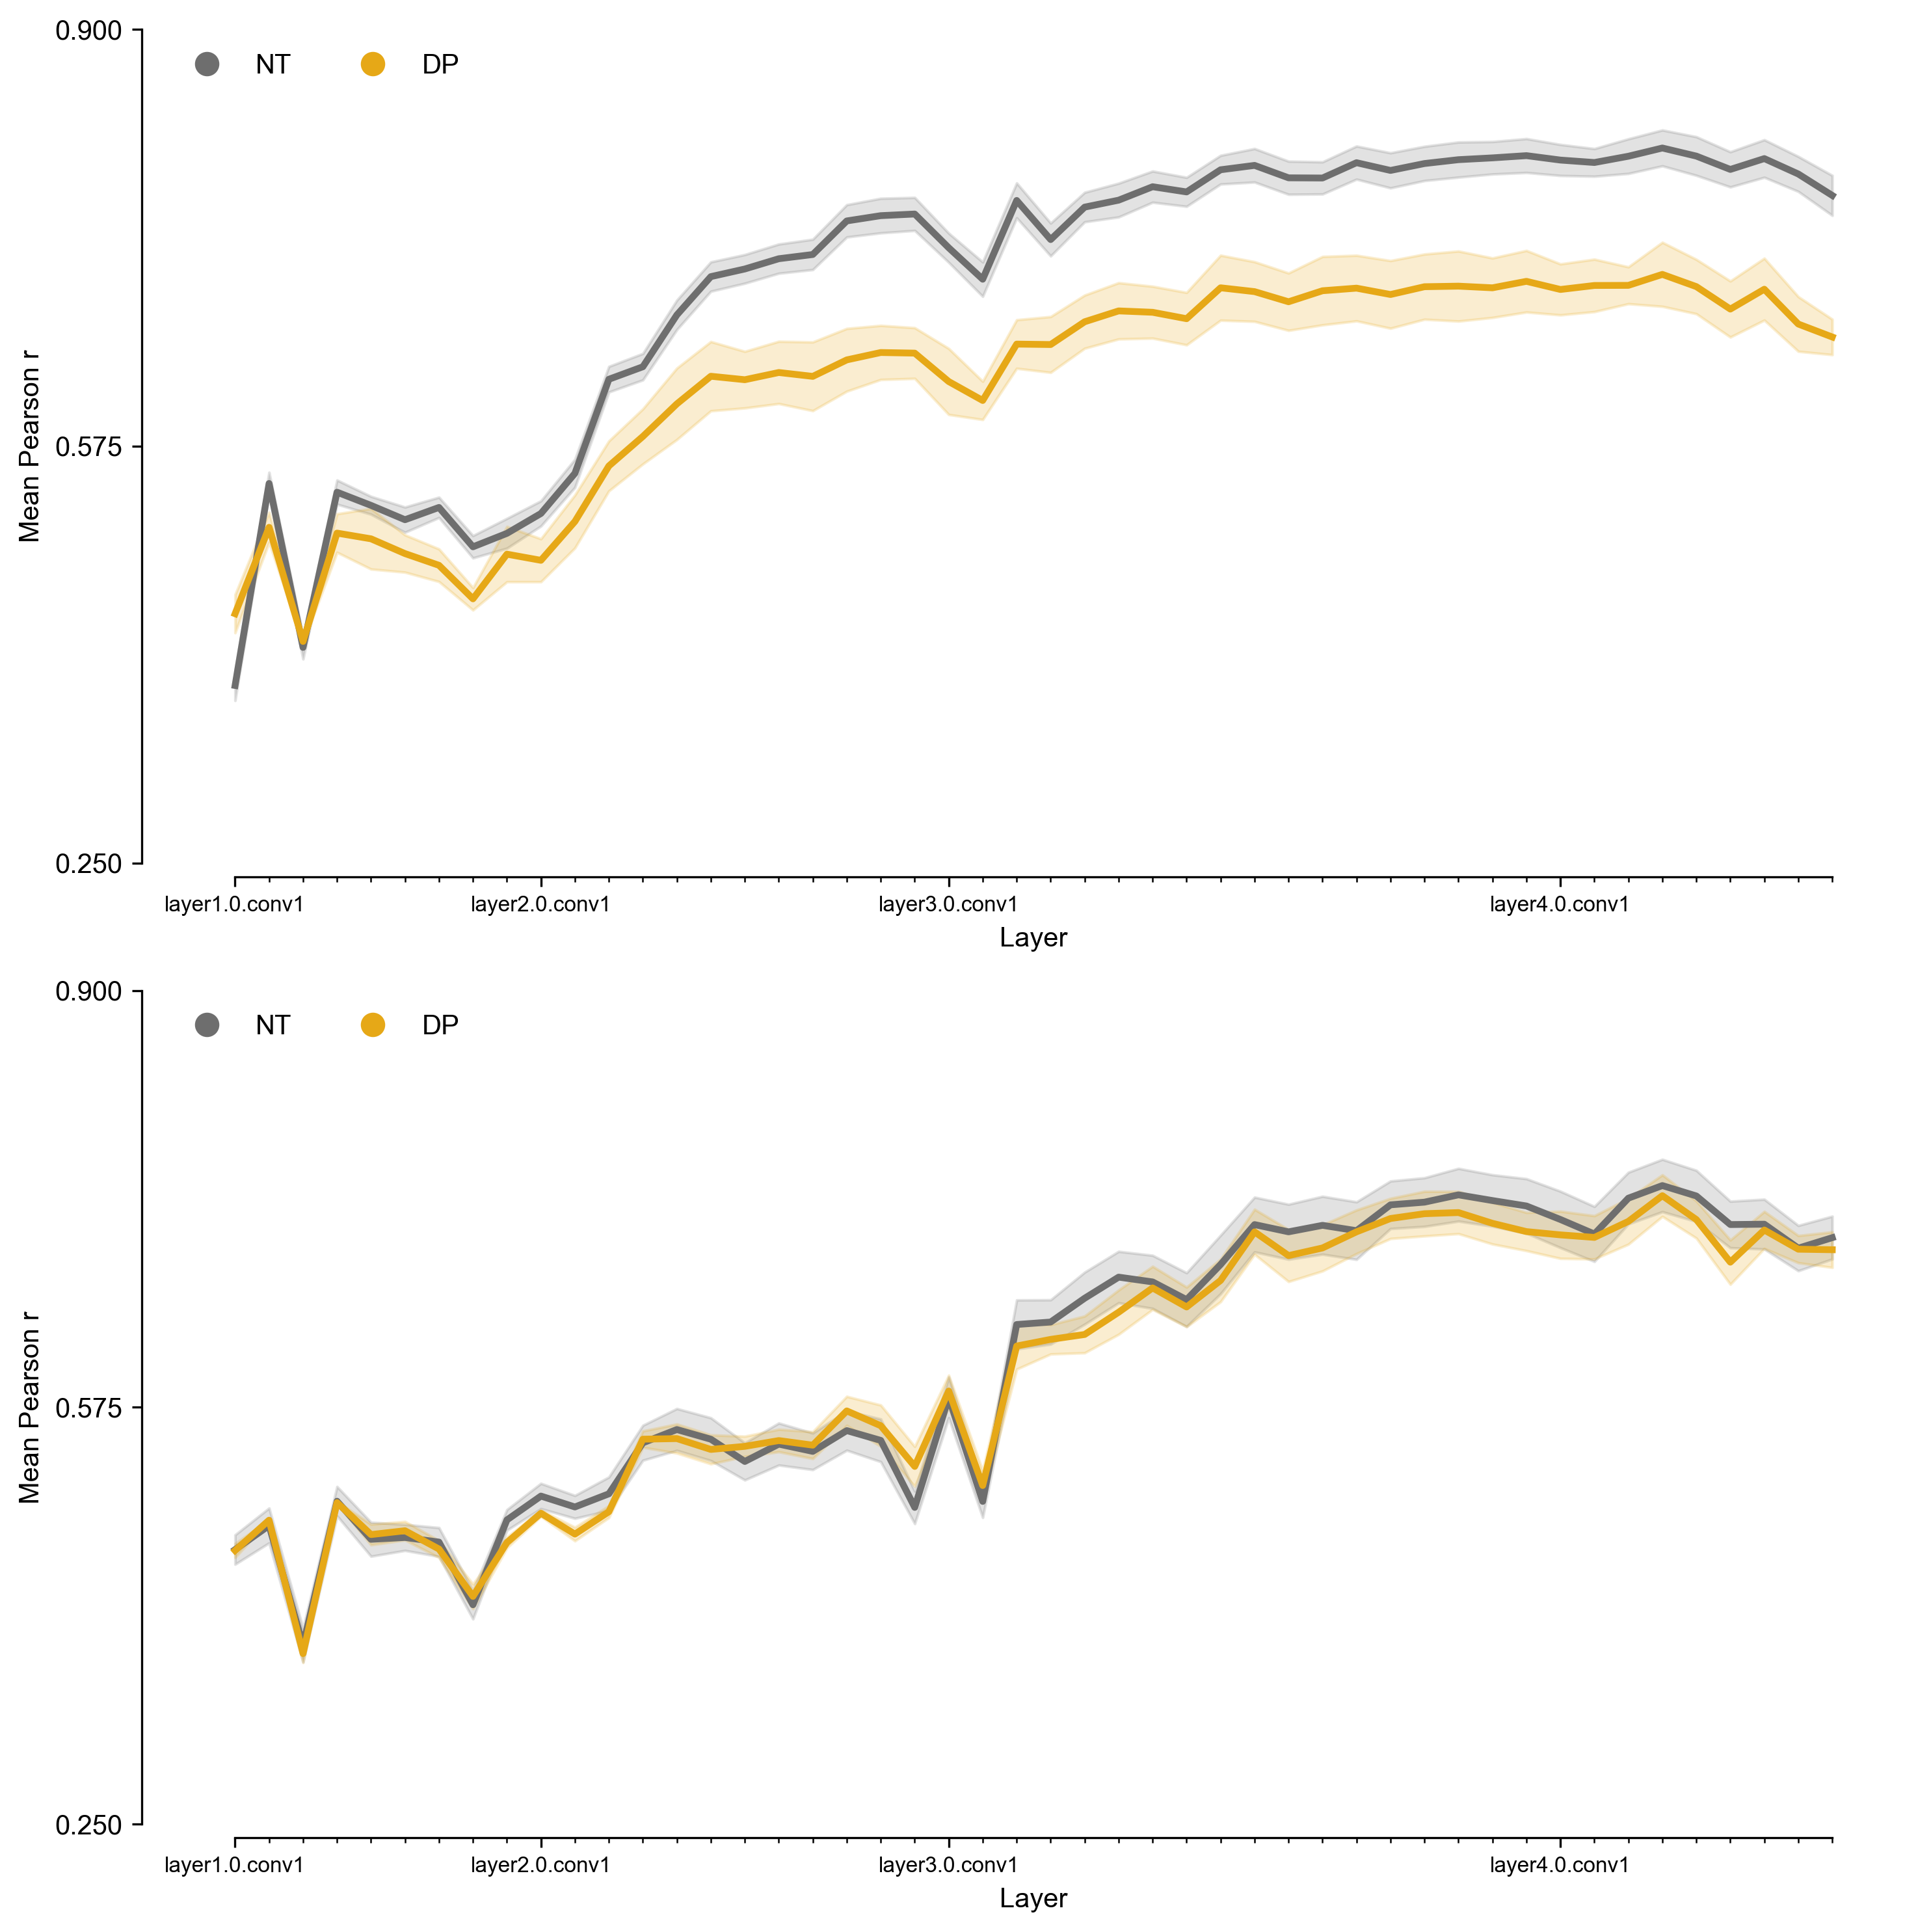

In [6]:
savefig = True
plot_dir = 'results/plots'
os.makedirs(plot_dir, exist_ok=True)

results_df = pt1_df.copy()
# frois = results_df['froi'].unique()
# subject_types = results_df['subject_type'].unique()
frois = ['lffa', 'rffa', 'leba', 'reba']
cfrois = ['ffa', 'eba']
subject_types = ['nt', 'dp']
layers = sorted(results_df['layer'].unique())

# lffa 0.3150640128451543 0.8832909182573756
# rffa 0.2784276965821423 0.8694182060071649
# leba 0.2640283960572184 0.829614037026508
# reba 0.3516917631111745 0.8309376682388164
y_lims_pearsonr_ax1_dict = {
    'ffa': (0.25, 0.9),
    'eba': (0.25, 0.9),
}
# lffa 0.6122575760230597 0.8832909182573756
# rffa 0.7095269084857823 0.8694182060071649
# leba 0.5934274810759648 0.829614037026508
# reba 0.6732742342406927 0.8309376682388164
# y_lims_pearsonr_ax2_dict = {
#     'lffa': (0.6, 0.9),
#     'rffa': (0.7, 0.9),
#     'leba': (0.55, 0.85),
#     'reba': (0.65, 0.85)
# }
y_lims_pearsonr_ax2_dict = {
    'lffa': (0.5, 1),
    'rffa': (0.5, 1),
    'leba': (0.5, 1),
    'reba': (0.5, 1)
}
# lffa 0.2923971422132868 0.6792188651322243
# rffa 0.3645475534941328 0.6601696144408999
# leba 0.340658912567695 0.6335329226262706
# reba 0.3491076042957997 0.599140589564325
# y_lims_rdmr_ax3_dict = {
#     'lffa': (0.2, 0.7),
#     'rffa': (0.3, 0.7),
#     'leba': (0.3, 0.7),
#     'reba': (0.3, 0.6)
# }
y_lims_rdmr_ax3_dict = {
    'lffa': (0.25, 0.75),
    'rffa': (0.25, 0.75),
    'leba': (0.25, 0.75),
    'reba': (0.25, 0.75)
}

subtype_colors_dict = {
    'nt': '#6e6e6e',  # Blue 
    'dp': '#E6A817'   # Orange
}
boxwidths = 0.2

# fig, axs = plt.subplots(len(frois), 3, figsize=(15, 10), dpi=300)

fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 10),
    dpi=300,
    # gridspec_kw={'width_ratios': [1.5, 0.5, 0.5]}  # ax1 wider, ax2/ax3 narrower
)

for cidx, cfroi in enumerate(cfrois):
    # Plot 1: Line plot of layer (x-axis) vs pearson r (y-axis). 2 lines: NT/DP (hemisphere-averaged)
    ax1 = axs[cidx]
    for subject_type in subject_types:
        st_df = results_df[
            (results_df['froi'].isin([f'l{cfroi}', f'r{cfroi}'])) &
            (results_df['subject_type'] == subject_type)
        ]

        # First average across hemispheres per subject/layer, then across subjects
        hemi_averaged_df = (
            st_df
            .groupby(['test_subject', 'layer'], as_index=False)['mean_pearsonr']
            .mean()
        )
        mean_by_layer = hemi_averaged_df.groupby('layer')['mean_pearsonr'].mean()
        sem_by_layer = hemi_averaged_df.groupby('layer')['mean_pearsonr'].sem()
        layer_indices = [layers.index(layer) for layer in mean_by_layer.index]

        ax1.plot(
            layer_indices, mean_by_layer.values, linewidth=2.5,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            linestyle='-',
            label=f'{subject_type.upper()}'
        )
        ax1.fill_between(
            layer_indices,
            mean_by_layer.values - sem_by_layer.values,
            mean_by_layer.values + sem_by_layer.values,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            alpha=0.2
        )

    xticks_minor = np.arange(len(layers))
    xticks_major = []
    xticks_major_labels = []
    for lidx, layer in enumerate(layers):
        if '.0.conv1' in layer:
            xticks_major.append(lidx)
            xticks_major_labels.append(layer)
    xticks_minor = np.delete(xticks_minor, xticks_major)
    ax1.set_xlabel('Layer')
    ax1.set_ylabel(f'Mean Pearson r')
    # ax1.set_title(f'{froi} - Layer vs Pearson r')
    # Create custom legend
    legend_elements = [
        Line2D([0], [0], color=subtype_colors_dict['nt'], marker='o', markersize=8, lw=0, label='NT'),
        Line2D([0], [0], color=subtype_colors_dict['dp'], marker='o', markersize=8, lw=0, label='DP'),
    ]
    ax1.legend(handles=legend_elements, frameon=False, loc='upper left', ncol=2)
    # ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_position(('outward', 5))
    ax1.spines['left'].set_position(('outward', 5))
    ax1.spines['bottom'].set_bounds((np.min(xticks_major), np.max(xticks_minor)))
    # Add x-ticks
    ax1.set_xticks(xticks_major, minor=False)
    ax1.set_xticklabels(xticks_major_labels, fontsize=8) # , rotation=45
    ax1.set_xticks(xticks_minor, minor=True)
    # y-lims
    ax1.set_ylim(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1)))
    # Add y-ticks at min, max and their mid-point
    yticks = np.linspace(np.min(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))), np.max(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))), num=3)
    ax1.set_yticks(yticks)
    ax1.spines['left'].set_bounds(np.min(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))), np.max(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))))

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig1_acrosslayer_lineplots.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

plt.close()

## v1

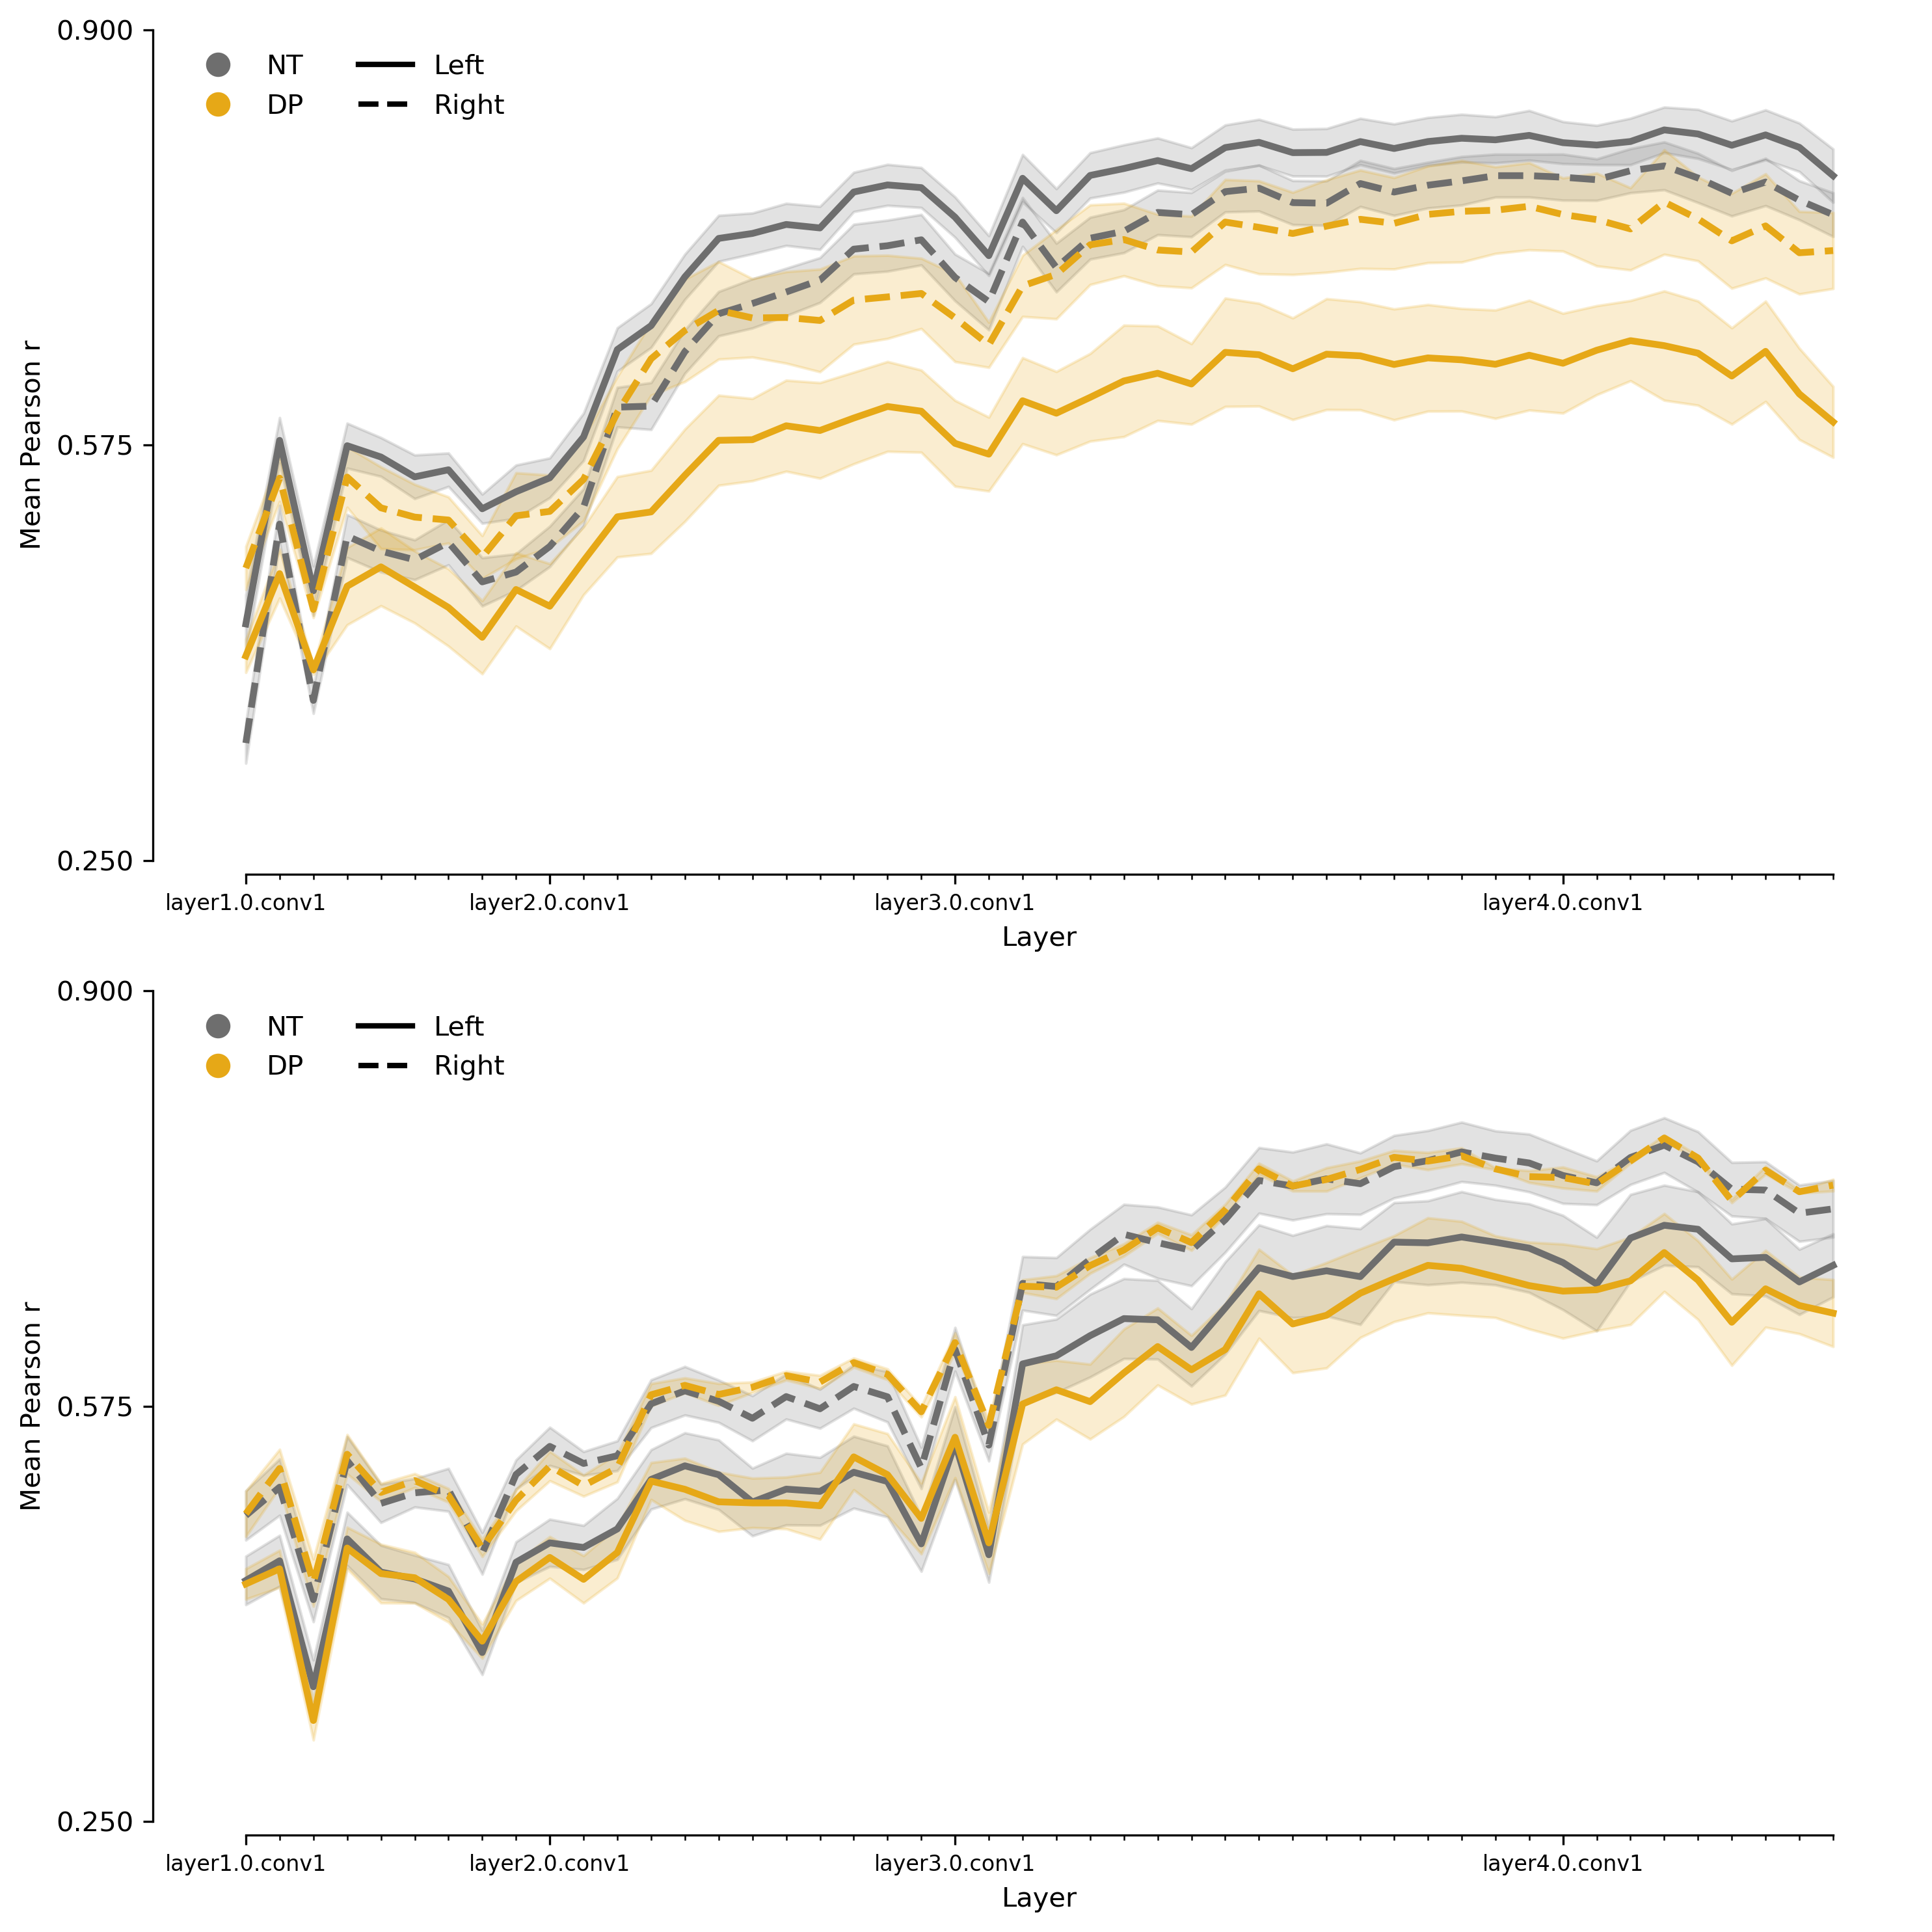

In [161]:
savefig = False
plot_dir = 'results/plots'
os.makedirs(plot_dir, exist_ok=True)

results_df = pt1_df.copy()
# frois = results_df['froi'].unique()
# subject_types = results_df['subject_type'].unique()
frois = ['lffa', 'rffa', 'leba', 'reba']
cfrois = ['ffa', 'eba']
hemis = ['l', 'r']
subject_types = ['nt', 'dp']
layers = sorted(results_df['layer'].unique())

# lffa 0.3150640128451543 0.8832909182573756
# rffa 0.2784276965821423 0.8694182060071649
# leba 0.2640283960572184 0.829614037026508
# reba 0.3516917631111745 0.8309376682388164
y_lims_pearsonr_ax1_dict = {
    'ffa': (0.25, 0.9),
    'eba': (0.25, 0.9),
}
# lffa 0.6122575760230597 0.8832909182573756
# rffa 0.7095269084857823 0.8694182060071649
# leba 0.5934274810759648 0.829614037026508
# reba 0.6732742342406927 0.8309376682388164
# y_lims_pearsonr_ax2_dict = {
#     'lffa': (0.6, 0.9),
#     'rffa': (0.7, 0.9),
#     'leba': (0.55, 0.85),
#     'reba': (0.65, 0.85)
# }
y_lims_pearsonr_ax2_dict = {
    'lffa': (0.5, 1),
    'rffa': (0.5, 1),
    'leba': (0.5, 1),
    'reba': (0.5, 1)
}
# lffa 0.2923971422132868 0.6792188651322243
# rffa 0.3645475534941328 0.6601696144408999
# leba 0.340658912567695 0.6335329226262706
# reba 0.3491076042957997 0.599140589564325
# y_lims_rdmr_ax3_dict = {
#     'lffa': (0.2, 0.7),
#     'rffa': (0.3, 0.7),
#     'leba': (0.3, 0.7),
#     'reba': (0.3, 0.6)
# }
y_lims_rdmr_ax3_dict = {
    'lffa': (0.25, 0.75),
    'rffa': (0.25, 0.75),
    'leba': (0.25, 0.75),
    'reba': (0.25, 0.75)
}

subtype_colors_dict = {
    'nt': '#6e6e6e',  # Blue 
    'dp': '#E6A817'   # Orange
}
hemitype_style_dict = {
    'l': '-',
    'r': '--'
}
boxwidths = 0.2

# fig, axs = plt.subplots(len(frois), 3, figsize=(15, 10), dpi=300)

fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 10),
    dpi=300,
    # gridspec_kw={'width_ratios': [1.5, 0.5, 0.5]}  # ax1 wider, ax2/ax3 narrower
)

for cidx, cfroi in enumerate(cfrois):
    # Plot 1: Line plot of layer (x-axis) vs pearson r (y-axis). 4 lines: NT/DP x L/R froi
    ax1 = axs[cidx]
    for subject_type in subject_types:
        for hemi_type in hemis:
            froi_df = results_df[results_df['froi'] == f'{hemi_type}{cfroi}']
            st_df = froi_df[froi_df['subject_type'] == subject_type]
            # for subject in st_df['test_subject'].unique():
            #     subject_df = st_df[st_df['test_subject'] == subject].sort_values('layer')
            #     ax1.plot(
            #         range(len(layers)), subject_df['mean_pearsonr'].values, alpha=0.25,
            #         color=subtype_colors_dict.get(subject_type, '#000000'),
            #         # label=subject_type if subject == st_df['test_subject'].unique()[0] else ""
            #     )
            # Mean line for subject type
            mean_by_layer = st_df.groupby('layer')['mean_pearsonr'].mean()
            sem_by_layer = st_df.groupby('layer')['mean_pearsonr'].sem()
            layer_indices = [layers.index(layer) for layer in mean_by_layer.index]
            ax1.plot(
                layer_indices, mean_by_layer.values, linewidth=2.5,
                color=subtype_colors_dict.get(subject_type, '#000000'),
                linestyle=hemitype_style_dict.get(hemi_type, '-'),
                label=f'{subject_type.upper()}'
            )
            ax1.fill_between(
                layer_indices, 
                mean_by_layer.values - sem_by_layer.values,
                mean_by_layer.values + sem_by_layer.values,
                color=subtype_colors_dict.get(subject_type, '#000000'),
                alpha=0.2
            )
    xticks_minor = np.arange(len(layers))
    xticks_major = []
    xticks_major_labels = []
    for lidx, layer in enumerate(layers):
        if '.0.conv1' in layer:
            xticks_major.append(lidx)
            xticks_major_labels.append(layer)
    xticks_minor = np.delete(xticks_minor, xticks_major)
    ax1.set_xlabel('Layer')
    ax1.set_ylabel(f'Mean Pearson r')
    # ax1.set_title(f'{froi} - Layer vs Pearson r')
    # Create custom legend
    legend_elements = [
        Line2D([0], [0], color=subtype_colors_dict['nt'], marker='o', markersize=8, lw=0, label='NT'),
        Line2D([0], [0], color=subtype_colors_dict['dp'], marker='o', markersize=8, lw=0, label='DP'),
        Line2D([0], [0], color='k', lw=2, linestyle='-', label='Left'),
        Line2D([0], [0], color='k', lw=2, linestyle='--', label='Right'),
    ]
    ax1.legend(handles=legend_elements, frameon=False, loc='upper left', ncol=2)
    # ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_position(('outward', 5))
    ax1.spines['left'].set_position(('outward', 5))
    ax1.spines['bottom'].set_bounds((np.min(xticks_major), np.max(xticks_minor)))
    # Add x-ticks
    ax1.set_xticks(xticks_major, minor=False)
    ax1.set_xticklabels(xticks_major_labels, fontsize=8) # , rotation=45
    ax1.set_xticks(xticks_minor, minor=True)
    # y-lims
    ax1.set_ylim(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1)))
    # Add y-ticks at min, max and their mid-point
    yticks = np.linspace(np.min(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))), np.max(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))), num=3)
    ax1.set_yticks(yticks)
    ax1.spines['left'].set_bounds(np.min(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))), np.max(y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))))

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig1_lineplots.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

plt.close()

# for i, froi in enumerate(frois):
#     froi_df = results_df[results_df['froi'] == froi]
    
#     # Plot 1: Layer vs mean_pearsonr with lines for each subject and subject type
#     ax1 = axs[i, 0]
#     for subject_type in subject_types:
#         st_df = froi_df[froi_df['subject_type'] == subject_type]
#         for subject in st_df['test_subject'].unique():
#             subject_df = st_df[st_df['test_subject'] == subject].sort_values('layer')
#             ax1.plot(
#                 range(len(layers)), subject_df['mean_pearsonr'].values, alpha=0.25,
#                 color=subtype_colors_dict.get(subject_type, '#000000'),
#                 # label=subject_type if subject == st_df['test_subject'].unique()[0] else ""
#             )
        
#         # Mean line for subject type
#         mean_by_layer = st_df.groupby('layer')['mean_pearsonr'].mean()
#         layer_indices = [layers.index(layer) for layer in mean_by_layer.index]
#         ax1.plot(
#             layer_indices, mean_by_layer.values, linewidth=2.5,
#             color=subtype_colors_dict.get(subject_type, '#000000'),
#             label=f'{subject_type.upper()}'
#         )
#     xticks_minor = np.arange(len(layers))
#     xticks_major = []
#     xticks_major_labels = []
#     for lidx, layer in enumerate(layers):
#         if '.0.conv1' in layer:
#             xticks_minor = np.delete(xticks_minor, lidx)
#             xticks_major.append(lidx)
#             xticks_major_labels.append(layer)
#     ax1.set_xlabel('Layer')
#     ax1.set_ylabel(f'{froi.upper()}\nMean Pearson r')
#     # ax1.set_title(f'{froi} - Layer vs Pearson r')
#     ax1.legend(frameon=False)
#     # ax1.grid(True, alpha=0.3)
#     ax1.spines['top'].set_visible(False)
#     ax1.spines['right'].set_visible(False)
#     ax1.spines['bottom'].set_position(('outward', 5))
#     ax1.spines['left'].set_position(('outward', 5))
#     ax1.spines['bottom'].set_bounds((np.min(xticks_major), np.max(xticks_minor)))
#     # Add x-ticks
#     ax1.set_xticks(xticks_major, minor=False)
#     ax1.set_xticklabels(xticks_major_labels, rotation=45, fontsize=6)
#     ax1.set_xticks(xticks_minor, minor=True)
#     # y-lims
#     ax1.set_ylim(y_lims_pearsonr_dict.get(froi, (0, 1)))
#     # Add y-ticks at min, max and their mid-point
#     yticks = np.linspace(np.min(y_lims_pearsonr_dict.get(froi, (0, 1))), np.max(y_lims_pearsonr_dict.get(froi, (0, 1))), num=3)
#     ax1.set_yticks(yticks)
#     ax1.spines['left'].set_bounds(np.min(y_lims_pearsonr_dict.get(froi, (0, 1))), np.max(y_lims_pearsonr_dict.get(froi, (0, 1))))

#     # Plot 2: Box plot - subject type vs mean_pearsonr
#     ax2 = axs[i, 1]
#     data_pearsonr = [
#         froi_df[froi_df['subject_type'] == st].groupby('test_subject')['mean_pearsonr'].max().values
#         for st in subject_types
#     ]
#     box_positions = np.arange(len(subject_types)) * 0.55 + 1.0  # tighter spacing
#     ax2.boxplot(
#         data_pearsonr, positions=box_positions, widths=boxwidths,
#         medianprops = {'color': 'black', 'linewidth': 2},
#         tick_labels=[st_.upper() for st_ in subject_types], showfliers=False
#     )
#     # Overlay actual points
#     rng = np.random.default_rng(0)
#     for pos, st, vals in zip(box_positions, subject_types, data_pearsonr):
#         # x_jitter = rng.uniform(-0.06, 0.06, size=len(vals))
#         ax2.scatter(
#             np.full(len(vals), pos),
#             vals,
#             s=30,
#             alpha=0.9,
#             color=subtype_colors_dict.get(st, '#000000'),
#             edgecolor='white',
#             linewidth=0.4,
#             zorder=3
#         )
#     ax2.set_xlim(box_positions[0] - 0.3, box_positions[-1] + 0.3)
#     ax2.set_ylabel('Mean Pearson r')
#     # ax2.set_title(f'{froi} - Subject Type vs Pearson r')
#     ax2.spines['top'].set_visible(False)
#     ax2.spines['right'].set_visible(False)
#     ax2.spines['bottom'].set_position(('outward', 5))
#     ax2.spines['left'].set_position(('outward', 5))
#     ax2.spines['bottom'].set_bounds((box_positions[0], box_positions[-1]))
#     ax2.set_ylim(y_lims_pearsonr_ax2_dict.get(froi, (0, 1)))
#     yticks2 = np.linspace(*y_lims_pearsonr_ax2_dict.get(froi, (0, 1)), num=3)
#     ax2.set_yticks(yticks2)
#     ax2.spines['left'].set_bounds(*y_lims_pearsonr_ax2_dict.get(froi, (0, 1)))

#     # Plot 3: Box plot - subject type vs mean_rdmr
#     ax3 = axs[i, 2]
#     data_rdmr = [
#         froi_df[froi_df['subject_type'] == st].groupby('test_subject')['mean_rdmr'].max().values
#         for st in subject_types
#     ]
#     ax3.boxplot(
#         data_rdmr, positions=box_positions, widths=boxwidths,
#         medianprops = {'color': 'black', 'linewidth': 2},
#         tick_labels=[st_.upper() for st_ in subject_types], showfliers=False
#     )
#     # Overlay actual points
#     for pos, st, vals in zip(box_positions, subject_types, data_rdmr):
#         # x_jitter = rng.uniform(-0.06, 0.06, size=len(vals))
#         ax3.scatter(
#             np.full(len(vals), pos),
#             vals,
#             s=30,
#             alpha=0.9,
#             color=subtype_colors_dict.get(st, '#000000'),
#             edgecolor='white',
#             linewidth=0.4,
#             zorder=3
#         )
#     ax3.set_xlim(box_positions[0] - 0.3, box_positions[-1] + 0.3)
#     ax3.set_ylabel('Mean RDM r')
#     # ax3.set_title(f'{froi} - Subject Type vs RDM r')
#     ax3.spines['top'].set_visible(False)
#     ax3.spines['right'].set_visible(False)
#     ax3.spines['bottom'].set_position(('outward', 5))
#     ax3.spines['left'].set_position(('outward', 5))
#     ax3.spines['bottom'].set_bounds((box_positions[0], box_positions[-1]))

#     ax3.set_ylim(y_lims_rdmr_ax3_dict.get(froi, (0, 1)))
#     yticks3 = np.linspace(*y_lims_rdmr_ax3_dict.get(froi, (0, 1)), num=3)
#     ax3.set_yticks(yticks3)
#     ax3.spines['left'].set_bounds(*y_lims_rdmr_ax3_dict.get(froi, (0, 1)))

## v0 (TODO: fix ticks)

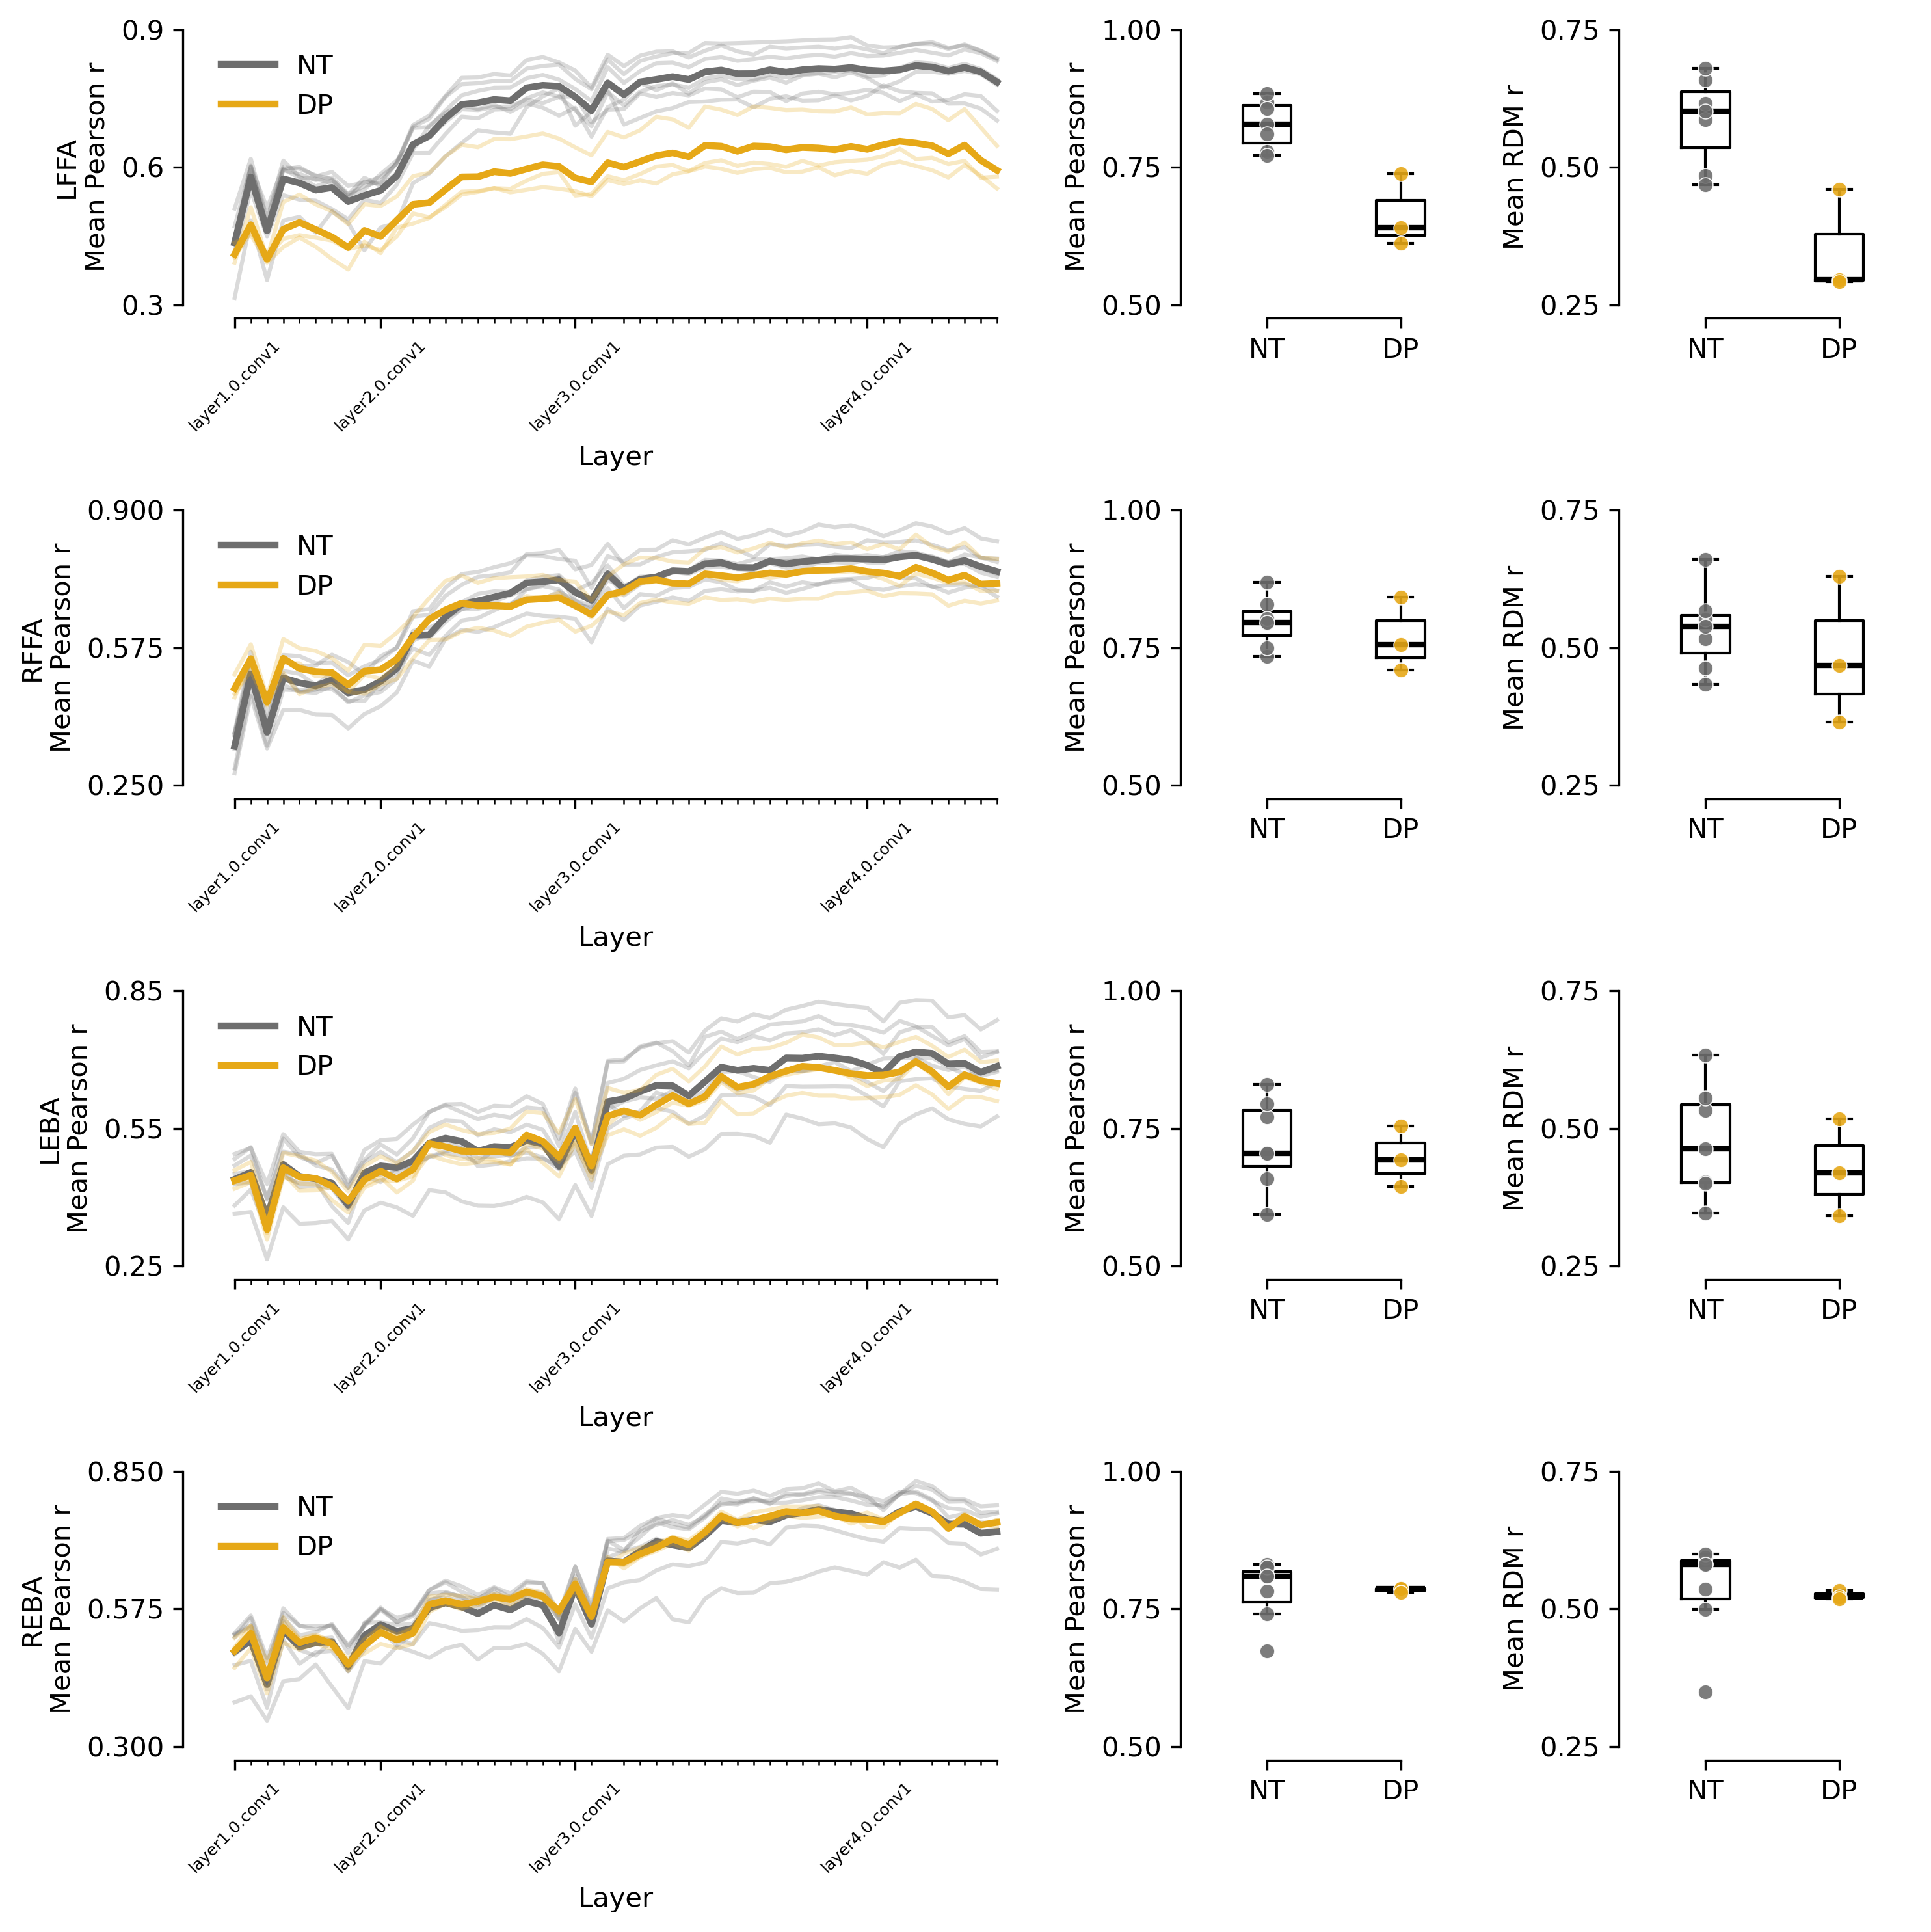

In [ ]:
savefig = True
plot_dir = 'results/plots'
os.makedirs(plot_dir, exist_ok=True)

results_df = pt1_df.copy()

frois = results_df['froi'].unique()
subject_types = results_df['subject_type'].unique()
layers = sorted(results_df['layer'].unique())

# lffa 0.3150640128451543 0.8832909182573756
# rffa 0.2784276965821423 0.8694182060071649
# leba 0.2640283960572184 0.829614037026508
# reba 0.3516917631111745 0.8309376682388164
y_lims_pearsonr_dict = {
    'lffa': (0.3, 0.9),
    'rffa': (0.25, 0.9),
    'leba': (0.25, 0.85),
    'reba': (0.3, 0.85)
}
# lffa 0.6122575760230597 0.8832909182573756
# rffa 0.7095269084857823 0.8694182060071649
# leba 0.5934274810759648 0.829614037026508
# reba 0.6732742342406927 0.8309376682388164
# y_lims_pearsonr_ax2_dict = {
#     'lffa': (0.6, 0.9),
#     'rffa': (0.7, 0.9),
#     'leba': (0.55, 0.85),
#     'reba': (0.65, 0.85)
# }
y_lims_pearsonr_ax2_dict = {
    'lffa': (0.5, 1),
    'rffa': (0.5, 1),
    'leba': (0.5, 1),
    'reba': (0.5, 1)
}
# lffa 0.2923971422132868 0.6792188651322243
# rffa 0.3645475534941328 0.6601696144408999
# leba 0.340658912567695 0.6335329226262706
# reba 0.3491076042957997 0.599140589564325
# y_lims_rdmr_ax3_dict = {
#     'lffa': (0.2, 0.7),
#     'rffa': (0.3, 0.7),
#     'leba': (0.3, 0.7),
#     'reba': (0.3, 0.6)
# }
y_lims_rdmr_ax3_dict = {
    'lffa': (0.25, 0.75),
    'rffa': (0.25, 0.75),
    'leba': (0.25, 0.75),
    'reba': (0.25, 0.75)
}

subtype_colors_dict = {
    'nt': '#6e6e6e',  # Blue 
    'dp': '#E6A817'   # Orange
}
boxwidths = 0.2

# fig, axs = plt.subplots(len(frois), 3, figsize=(15, 10), dpi=300)

fig, axs = plt.subplots(
    len(frois), 3,
    figsize=(10, 10),
    dpi=300,
    gridspec_kw={'width_ratios': [1.5, 0.5, 0.5]}  # ax1 wider, ax2/ax3 narrower
)


for i, froi in enumerate(frois):
    froi_df = results_df[results_df['froi'] == froi]
    
    # Plot 1: Layer vs mean_pearsonr with lines for each subject and subject type
    ax1 = axs[i, 0]
    for subject_type in subject_types:
        st_df = froi_df[froi_df['subject_type'] == subject_type]
        for subject in st_df['test_subject'].unique():
            subject_df = st_df[st_df['test_subject'] == subject].sort_values('layer')
            ax1.plot(
                range(len(layers)), subject_df['mean_pearsonr'].values, alpha=0.25,
                color=subtype_colors_dict.get(subject_type, '#000000'),
                # label=subject_type if subject == st_df['test_subject'].unique()[0] else ""
            )
        
        # Mean line for subject type
        mean_by_layer = st_df.groupby('layer')['mean_pearsonr'].mean()
        layer_indices = [layers.index(layer) for layer in mean_by_layer.index]
        ax1.plot(
            layer_indices, mean_by_layer.values, linewidth=2.5,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            label=f'{subject_type.upper()}'
        )
    xticks_minor = np.arange(len(layers))
    xticks_major = []
    xticks_major_labels = []
    for lidx, layer in enumerate(layers):
        if '.0.conv1' in layer:
            xticks_minor = np.delete(xticks_minor, lidx)
            xticks_major.append(lidx)
            xticks_major_labels.append(layer)
    ax1.set_xlabel('Layer')
    ax1.set_ylabel(f'{froi.upper()}\nMean Pearson r')
    # ax1.set_title(f'{froi} - Layer vs Pearson r')
    ax1.legend(frameon=False)
    # ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_position(('outward', 5))
    ax1.spines['left'].set_position(('outward', 5))
    ax1.spines['bottom'].set_bounds((np.min(xticks_major), np.max(xticks_minor)))
    # Add x-ticks
    ax1.set_xticks(xticks_major, minor=False)
    ax1.set_xticklabels(xticks_major_labels, rotation=45, fontsize=6)
    ax1.set_xticks(xticks_minor, minor=True)
    # y-lims
    ax1.set_ylim(y_lims_pearsonr_dict.get(froi, (0, 1)))
    # Add y-ticks at min, max and their mid-point
    yticks = np.linspace(np.min(y_lims_pearsonr_dict.get(froi, (0, 1))), np.max(y_lims_pearsonr_dict.get(froi, (0, 1))), num=3)
    ax1.set_yticks(yticks)
    ax1.spines['left'].set_bounds(np.min(y_lims_pearsonr_dict.get(froi, (0, 1))), np.max(y_lims_pearsonr_dict.get(froi, (0, 1))))

    # Plot 2: Box plot - subject type vs mean_pearsonr
    ax2 = axs[i, 1]
    data_pearsonr = [
        froi_df[froi_df['subject_type'] == st].groupby('test_subject')['mean_pearsonr'].max().values
        for st in subject_types
    ]
    box_positions = np.arange(len(subject_types)) * 0.55 + 1.0  # tighter spacing
    ax2.boxplot(
        data_pearsonr, positions=box_positions, widths=boxwidths,
        medianprops = {'color': 'black', 'linewidth': 2},
        tick_labels=[st_.upper() for st_ in subject_types], showfliers=False
    )
    # Overlay actual points
    rng = np.random.default_rng(0)
    for pos, st, vals in zip(box_positions, subject_types, data_pearsonr):
        # x_jitter = rng.uniform(-0.06, 0.06, size=len(vals))
        ax2.scatter(
            np.full(len(vals), pos),
            vals,
            s=30,
            alpha=0.9,
            color=subtype_colors_dict.get(st, '#000000'),
            edgecolor='white',
            linewidth=0.4,
            zorder=3
        )
    ax2.set_xlim(box_positions[0] - 0.3, box_positions[-1] + 0.3)
    ax2.set_ylabel('Mean Pearson r')
    # ax2.set_title(f'{froi} - Subject Type vs Pearson r')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.spines['bottom'].set_position(('outward', 5))
    ax2.spines['left'].set_position(('outward', 5))
    ax2.spines['bottom'].set_bounds((box_positions[0], box_positions[-1]))
    ax2.set_ylim(y_lims_pearsonr_ax2_dict.get(froi, (0, 1)))
    yticks2 = np.linspace(*y_lims_pearsonr_ax2_dict.get(froi, (0, 1)), num=3)
    ax2.set_yticks(yticks2)
    ax2.spines['left'].set_bounds(*y_lims_pearsonr_ax2_dict.get(froi, (0, 1)))

    # Plot 3: Box plot - subject type vs mean_rdmr
    ax3 = axs[i, 2]
    data_rdmr = [
        froi_df[froi_df['subject_type'] == st].groupby('test_subject')['mean_rdmr'].max().values
        for st in subject_types
    ]
    ax3.boxplot(
        data_rdmr, positions=box_positions, widths=boxwidths,
        medianprops = {'color': 'black', 'linewidth': 2},
        tick_labels=[st_.upper() for st_ in subject_types], showfliers=False
    )
    # Overlay actual points
    for pos, st, vals in zip(box_positions, subject_types, data_rdmr):
        # x_jitter = rng.uniform(-0.06, 0.06, size=len(vals))
        ax3.scatter(
            np.full(len(vals), pos),
            vals,
            s=30,
            alpha=0.9,
            color=subtype_colors_dict.get(st, '#000000'),
            edgecolor='white',
            linewidth=0.4,
            zorder=3
        )
    ax3.set_xlim(box_positions[0] - 0.3, box_positions[-1] + 0.3)
    ax3.set_ylabel('Mean RDM r')
    # ax3.set_title(f'{froi} - Subject Type vs RDM r')
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.spines['bottom'].set_position(('outward', 5))
    ax3.spines['left'].set_position(('outward', 5))
    ax3.spines['bottom'].set_bounds((box_positions[0], box_positions[-1]))

    ax3.set_ylim(y_lims_rdmr_ax3_dict.get(froi, (0, 1)))
    yticks3 = np.linspace(*y_lims_rdmr_ax3_dict.get(froi, (0, 1)), num=3)
    ax3.set_yticks(yticks3)
    ax3.spines['left'].set_bounds(*y_lims_rdmr_ax3_dict.get(froi, (0, 1)))

plt.tight_layout()

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig1_v0.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

plt.close()

# Part 2

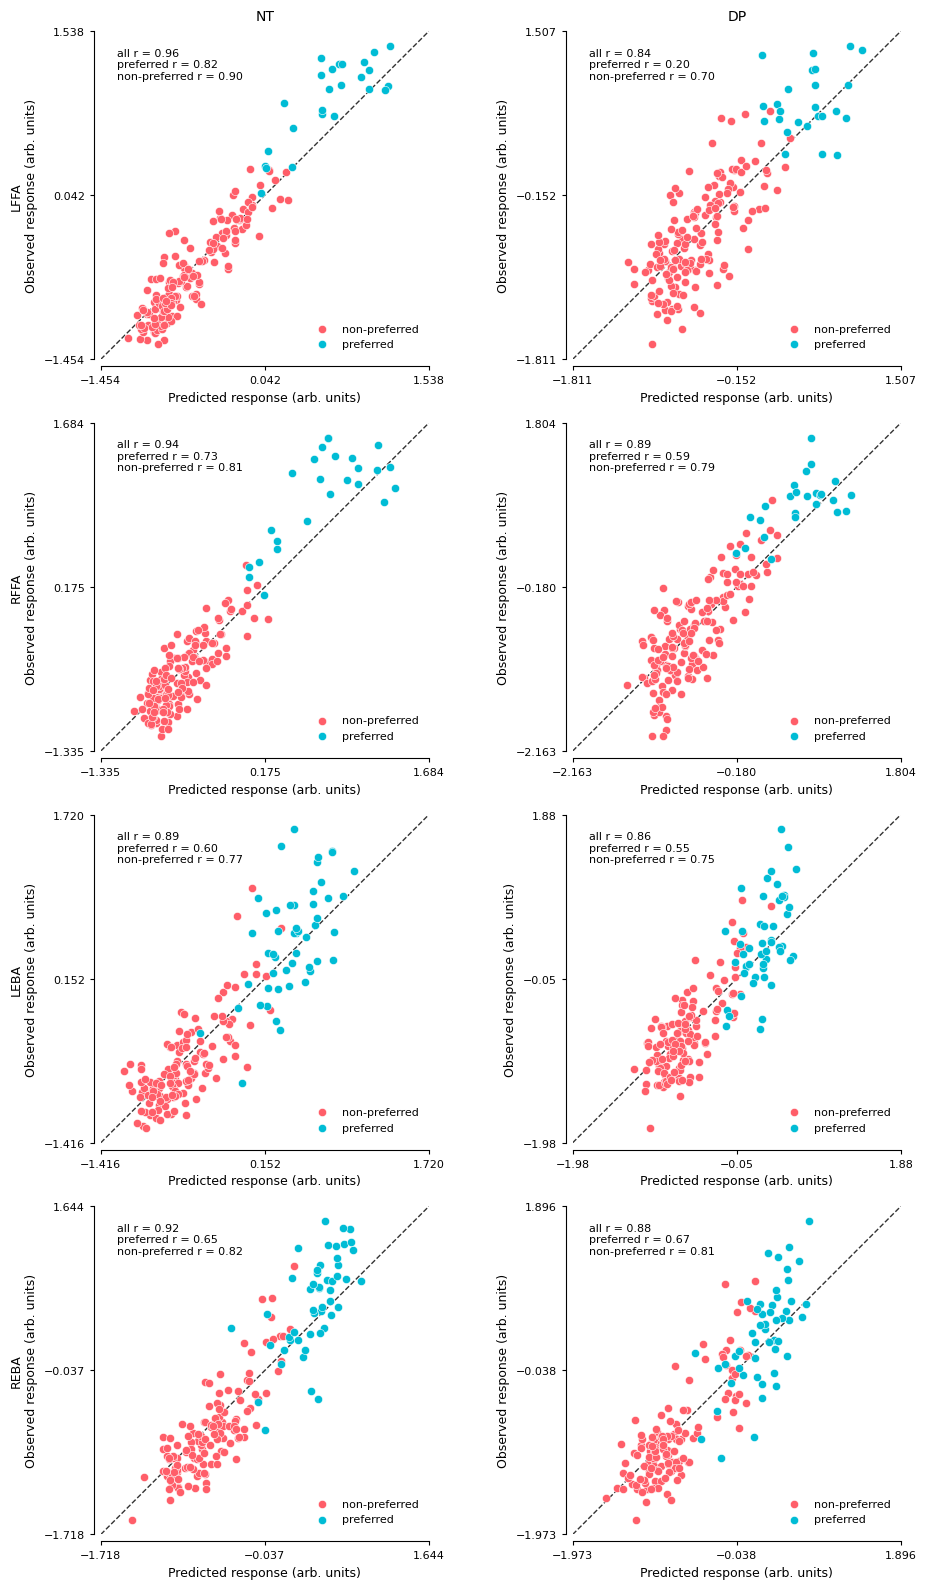

In [ ]:
savefig=True

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')
# subtypes = results_csv['subject_type'].unique()
subtypes = ['nt', 'dp']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']

fig, axs = plt.subplots(len(frois_considered), len(subtypes), figsize=(10, 16), sharex=False, sharey=False)

for i, froi in enumerate(frois_considered):
    for j, subtype in enumerate(subtypes):
        ax = axs[i, j]

        preferred_stim = None
        if 'ffa' in froi:
            preferred_stim = 'faces'
        elif 'eba' in froi:
            preferred_stim = 'bodies'

        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        df_final = (
            df_stage1
            .groupby(['overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        mask_preferred = df_final['img_cat'] == preferred_stim
        mask_nonpreferred = ~mask_preferred

        r_preferred, _ = pearsonr(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed']
        )
        r_nonpreferred, _ = pearsonr(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed']
        )
        r_all, _ = pearsonr(df_final['y_prediction'], df_final['y_observed'])

        # scatter points
        ax.scatter(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed'],
            color='#ff5e69',
            alpha=1,
            s=35,
            edgecolor='white',
            linewidth=0.4,
            label='non-preferred',
            zorder=3
        )
        ax.scatter(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed'],
            color='#00bcd5',
            alpha=1,
            s=35,
            edgecolor='white',
            linewidth=0.4,
            label='preferred',
            zorder=3
        )

        lims = [
            min(df_final['y_prediction'].min(), df_final['y_observed'].min()),
            max(df_final['y_prediction'].max(), df_final['y_observed'].max())
        ]
        pad = 0.05 * (lims[1] - lims[0])
        lims = [lims[0] - pad, lims[1] + pad]

        ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.8, zorder=2)
        ax.set_xlim(lims)
        ax.set_ylim(lims)

        if i==0:
            ax.set_title(subtype.upper(), fontsize=10, pad=8)
        ax.set_xlabel('Predicted response (arb. units)', fontsize=9)
        if j==0:
            ax.set_ylabel(f'{froi.upper()}\nObserved response (arb. units)', fontsize=9)
        else:
            ax.set_ylabel('Observed response (arb. units)', fontsize=9)

        ax.text(
            0.05, 0.95,
            f'all r = {r_all:.2f}\npreferred r = {r_preferred:.2f}\nnon-preferred r = {r_nonpreferred:.2f}',
            transform=ax.transAxes,
            va='top',
            fontsize=8,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=2)
        )

        ax.legend(fontsize=8, frameon=False, loc='lower right')
        ax.set_aspect('equal', adjustable='box')

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_bounds(*lims)
        ax.spines['left'].set_bounds(*lims)

        ax.tick_params(axis='both', labelsize=8, length=3, width=0.8)
        ax.set_xticks(np.linspace(*lims, num=3))
        ax.set_yticks(np.linspace(*lims, num=3))

plt.tight_layout()
for ax in axs.flat:
    ax.set_box_aspect(1)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2_v0.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

lffa p-values - All r: 6.892098554810175e-102, Preferred r: 6.470591376765016e-07, Non-preferred r: 2.064639818027182e-59
lffa p-values - All r: 2.3708849645581086e-50, Preferred r: 0.3404814418316912, Non-preferred r: 3.2603510971904867e-25
rffa p-values - All r: 1.5459153787648917e-89, Preferred r: 3.5480525085847394e-05, Non-preferred r: 8.624256082593896e-39
rffa p-values - All r: 1.9822717819963864e-63, Preferred r: 0.002002610245131533, Non-preferred r: 1.086434667069583e-34
leba p-values - All r: 4.96453054583281e-65, Preferred r: 3.829763275307167e-06, Non-preferred r: 2.4201637693127297e-27
leba p-values - All r: 7.384670745686688e-55, Preferred r: 3.908994921414518e-05, Non-preferred r: 7.291430258234464e-26
reba p-values - All r: 1.894038490423808e-75, Preferred r: 3.2090111516225815e-07, Non-preferred r: 7.96846920583235e-34
reba p-values - All r: 2.1699093608187405e-62, Preferred r: 1.0381519181469658e-07, Non-preferred r: 2.481197788282481e-32


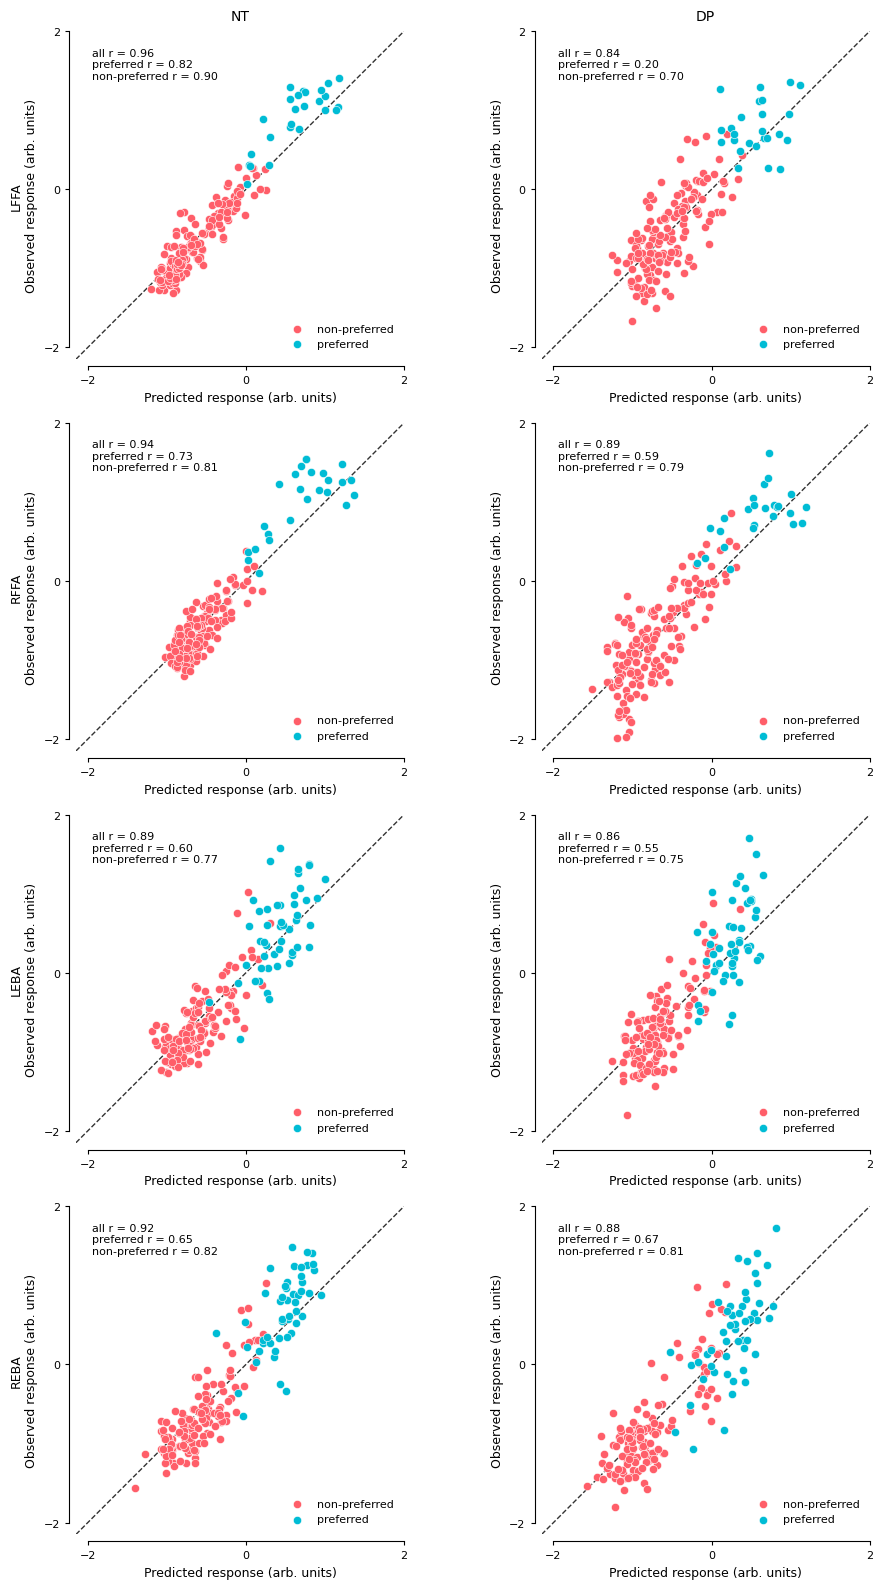

In [134]:
savefig = False

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')
# subtypes = results_csv['subject_type'].unique()
subtypes = ['nt', 'dp']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']

fig, axs = plt.subplots(len(frois_considered), len(subtypes), figsize=(10, 16), sharex=False, sharey=False)

# First pass: collect all data and calculate global limits for each FROI
# froi_limits = {}
# for i, froi in enumerate(frois_considered):
#     all_predictions = []
#     all_observations = []
    
#     for j, subtype in enumerate(subtypes):
#         df_sub = results_csv[
#             (results_csv['froi'] == froi) &
#             (results_csv['subject_type'] == subtype)
#         ].copy()

#         df_stage1 = (
#             df_sub
#             .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
#             .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
#         )

#         df_final = (
#             df_stage1
#             .groupby(['overall_img_idx', 'img_cat'], as_index=False)
#             .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
#         )
        
#         all_predictions.extend(df_final['y_prediction'].values)
#         all_observations.extend(df_final['y_observed'].values)
    
#     # Calculate limits for this FROI
#     min_val = min(min(all_predictions), min(all_observations))
#     max_val = max(max(all_predictions), max(all_observations))
#     pad = 0.05 * (max_val - min_val)
#     froi_limits[froi] = [min_val - pad, max_val + pad]

froi_limits = {
    'lffa': [-2.15, 2],
    'rffa': [-2.15, 2],
    'leba': [-2.15, 2],
    'reba': [-2.15, 2]
}
froi_ticks = {
    'lffa': [-2, 0, 2],
    'rffa': [-2, 0, 2],
    'leba': [-2, 0, 2],
    'reba': [-2, 0, 2]
}

# Second pass: plot with consistent limits per FROI
for i, froi in enumerate(frois_considered):
    for j, subtype in enumerate(subtypes):
        ax = axs[i, j]

        preferred_stim = None
        if 'ffa' in froi:
            preferred_stim = 'faces'
        elif 'eba' in froi:
            preferred_stim = 'bodies'

        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        df_final = (
            df_stage1
            .groupby(['overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        mask_preferred = df_final['img_cat'] == preferred_stim
        mask_nonpreferred = ~mask_preferred

        r_preferred, pval_preferred = pearsonr(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed']
        )
        r_nonpreferred, pval_nonpreferred = pearsonr(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed']
        )
        r_all, pval_all = pearsonr(df_final['y_prediction'], df_final['y_observed'])
        print(f'{froi} p-values - All r: {pval_all}, Preferred r: {pval_preferred}, Non-preferred r: {pval_nonpreferred}')

        # scatter points
        ax.scatter(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed'],
            color='#ff5e69',
            alpha=1,
            s=35,
            edgecolor='white',
            linewidth=0.4,
            label='non-preferred',
            zorder=3
        )
        ax.scatter(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed'],
            color='#00bcd5',
            alpha=1,
            s=35,
            edgecolor='white',
            linewidth=0.4,
            label='preferred',
            zorder=3
        )

        lims = froi_limits[froi]

        ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.8, zorder=2)
        ax.set_xlim(lims)
        ax.set_ylim(lims)

        if i==0:
            ax.set_title(subtype.upper(), fontsize=10, pad=8)
        ax.set_xlabel('Predicted response (arb. units)', fontsize=9)
        if j==0:
            ax.set_ylabel(f'{froi.upper()}\nObserved response (arb. units)', fontsize=9)
        else:
            ax.set_ylabel('Observed response (arb. units)', fontsize=9)

        ax.text(
            0.05, 0.95,
            f'all r = {r_all:.2f}\npreferred r = {r_preferred:.2f}\nnon-preferred r = {r_nonpreferred:.2f}',
            transform=ax.transAxes,
            va='top',
            fontsize=8,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=2)
        )

        ax.legend(fontsize=8, frameon=False, loc='lower right')
        ax.set_aspect('equal', adjustable='box')

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_position(('outward', 5))
        ticks = np.array(froi_ticks.get(froi, []))
        ax.spines['bottom'].set_bounds(ticks.min(), ticks.max())
        ax.spines['left'].set_bounds(ticks.min(), ticks.max())

        ax.tick_params(axis='both', labelsize=8, length=3, width=0.8)
        ax.set_xticks(froi_ticks.get(froi, []))
        ax.set_yticks(froi_ticks.get(froi, []))

plt.tight_layout()
for ax in axs.flat:
    ax.set_box_aspect(1)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_part2_analysis.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()